# How far do 2D molecular representations generalize?
### HOMO–LUMO gap prediction on QM9 under random and scaffold splits
**Koroush Mashayekh** — University of Padova

This notebook runs the whole project on Google Colab, step by step, and shows the outputs of the final run.
The code is in `src/qm9gap/` and `scripts/`; the full description of the methods and results is in `README.md`.

## Step 0 — Setup
Mount Google Drive, go to the project folder and install the required packages
(RDKit, LightGBM, XGBoost, scikit-learn, pandas).

* The raw data (`qm9.sdf`, `qm9.sdf.csv`) is downloaded by the next cell into `MyDrive/QM9_Molecular_Property_Prediction/data/raw/`.
* All outputs are written to `MyDrive/QM9_Molecular_Property_Prediction/v2/`, outside the code folder,
  so replacing the code never deletes results.
* If the project folder is somewhere else in your Drive, change the `%cd` path below.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/qm9-gap-generalization
!pip install -q -r requirements.txt

from IPython.display import Image, display
FIG = "/content/drive/MyDrive/QM9_Molecular_Property_Prediction/v2/results/figures"
def show(name, width=800):
    display(Image(f"{FIG}/{name}", width=width))

Mounted at /content/drive
/content/drive/MyDrive/qm9-gap-generalization


### Download the data
QM9 in the SDF + CSV version distributed by DeepChem for MoleculeNet
(`https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/gdb9.tar.gz`), saved as `qm9.sdf` and `qm9.sdf.csv` in
`MyDrive/QM9_Molecular_Property_Prediction/data/raw/`. Skipped if the files are already there.

In [2]:
!python scripts/00_download_data.py

## Step 1 — Data preparation

**Goal:** read QM9 once, check data quality, and save clean molecular representations for all later steps.

- **Input:** `qm9.sdf` (133,885 molecules) and `qm9.sdf.csv` (DFT properties, B3LYP/6-31G(2df,p))
- **Target:** HOMO–LUMO gap, converted from Hartree to eV
- **For each molecule:** SMILES, Bemis–Murcko scaffold, 217 RDKit 2D descriptors,
  and a count-based Morgan fingerprint (radius 2, 2,048 bins), all from the heavy-atom graph
- **Data quality:** 1,688 records that RDKit cannot read and 5,638 records read as radicals
  (impossible for closed-shell QM9 molecules) are excluded → **126,559 molecules kept**
- **Descriptors:** 27 constant descriptors removed → **190 descriptors**, no missing values
- **Resumable:** processed in chunks of 10,000; about 20 min on Colab

**Output:** `processed/molecules.parquet`, `descriptors.parquet`, `morgan_counts.npy`,
`prepare_report.json`, `excluded_radicals.csv`

In [3]:
!python scripts/01_prepare_data.py

SDF records: 133,885
records       0- 10,000 done |   1.4 min
records  10,000- 20,000 done |   2.9 min
records  20,000- 30,000 done |   4.3 min
records  30,000- 40,000 done |   5.7 min
records  40,000- 50,000 done |   7.3 min
records  50,000- 60,000 done |   8.9 min
records  60,000- 70,000 done |  10.5 min
records  70,000- 80,000 done |  12.1 min
records  80,000- 90,000 done |  13.6 min
records  90,000-100,000 done |  15.1 min
records 100,000-110,000 done |  16.6 min
records 110,000-120,000 done |  18.1 min
records 120,000-130,000 done |  19.5 min
records 130,000-133,885 done |  20.0 min
sdf_records                        133885.0000
rejected_by_rdkit                    1688.0000
without_target                          0.0000
radicals_found                       5638.0000
radicals_excluded                    5638.0000
molecules_kept                     126559.0000
descriptors_computed                  217.0000
constant_descriptors_removed           27.0000
descriptors_kept             

## Step 2 — Train / validation / test splits

**Goal:** split the 126,559 molecules once, so that every later experiment uses exactly the same molecules.

- **Fractions:** 80% train, 10% validation, 10% test
- **Two split types:**
  - **Random:** molecules are assigned at random. This tests how well the model *interpolates* between similar molecules.
  - **Scaffold:** whole Bemis–Murcko scaffold groups go to one part only, so validation and test molecules have
    ring systems never seen in training. This tests how well the model *generalizes* to new chemotypes.
- **Three seeds** (0, 1, 2) for each split type, so results are reported as mean ± standard deviation.
- **Roles:** *train* fits the model, *validation* is used for every choice (model, hyperparameters, early stopping),
  and *test* is used only once, for the final score.

**Output:** `processed/splits.parquet` (one column per split and seed) and `results/split_summary.csv`.

In [4]:
!python scripts/02_make_splits.py

part          test   train    val
split                            
random_s0    12656  101247  12656
random_s1    12656  101247  12656
random_s2    12656  101247  12656
scaffold_s0  12657  101247  12655
scaffold_s1  12657  101247  12655
scaffold_s2  12657  101247  12655

Scaffolds per part:
part         test  train   val
split                         
random_s0    2982  12240  3016
random_s1    3088  12159  2979
random_s2    2949  12271  2961
scaffold_s0  2205  10778  1522
scaffold_s1  1820  10829  1856
scaffold_s2  1045  11917  1543

No scaffold is shared between train, val and test in any scaffold split.


## Step 3 — Model selection

**Goal:** choose the model with a fair protocol that was fixed before seeing any result.

- **Candidates (7 model families):** Ridge (linear), k-nearest neighbours, Random Forest, Extra Trees,
  LightGBM, XGBoost, and a neural network (MLP)
- **Equal budget:** each candidate tries 8 random hyperparameter settings, all trained on the same
  20,000 training molecules (RDKit descriptors, scaffold split, seed 0)
- **Scoring:** the best setting of each candidate is retrained on the full training set and scored on the
  **validation** set (scaffold and random split). **The test set is not used.**
- **Decision rule (fixed in advance):** lowest validation MAE on the scaffold split; models within 0.01 eV
  of the best are considered equally accurate, and the fastest of them is chosen
- **Resumable:** every finished configuration is saved; about 1.5–2 h on Colab

**Output:** `results/model_selection/model_selection_table.csv`, `selected_model.json`,
`results/figures/fig0_model_selection.png`

In [5]:
!python scripts/03_select_model.py


ridge: searching 8 configurations
    config 1/6  val MAE 0.3348 eV  (0.0 min)  {'alpha': 0.01}
    config 2/6  val MAE 0.3340 eV  (0.0 min)  {'alpha': 0.1}
    config 3/6  val MAE 0.3332 eV  (0.0 min)  {'alpha': 1.0}
    config 4/6  val MAE 0.3331 eV  (0.0 min)  {'alpha': 10.0}
    config 5/6  val MAE 0.3336 eV  (0.0 min)  {'alpha': 100.0}
    config 6/6  val MAE 0.3341 eV  (0.0 min)  {'alpha': 1000.0}
  best configuration: {'alpha': 10.0}
  full training set -> val MAE scaffold 0.3323 | random 0.3101 eV | fit 0.2 min

knn: searching 8 configurations
    config 1/8  val MAE 0.3605 eV  (0.0 min)  {'weights': 'uniform', 'n_neighbors': 3}
    config 2/8  val MAE 0.3593 eV  (0.0 min)  {'weights': 'distance', 'n_neighbors': 3}
    config 3/8  val MAE 0.3562 eV  (0.0 min)  {'weights': 'uniform', 'n_neighbors': 5}
    config 4/8  val MAE 0.3533 eV  (0.0 min)  {'weights': 'distance', 'n_neighbors': 5}
    config 5/8  val MAE 0.3556 eV  (0.0 min)  {'weights': 'uniform', 'n_neighbors': 10}
   

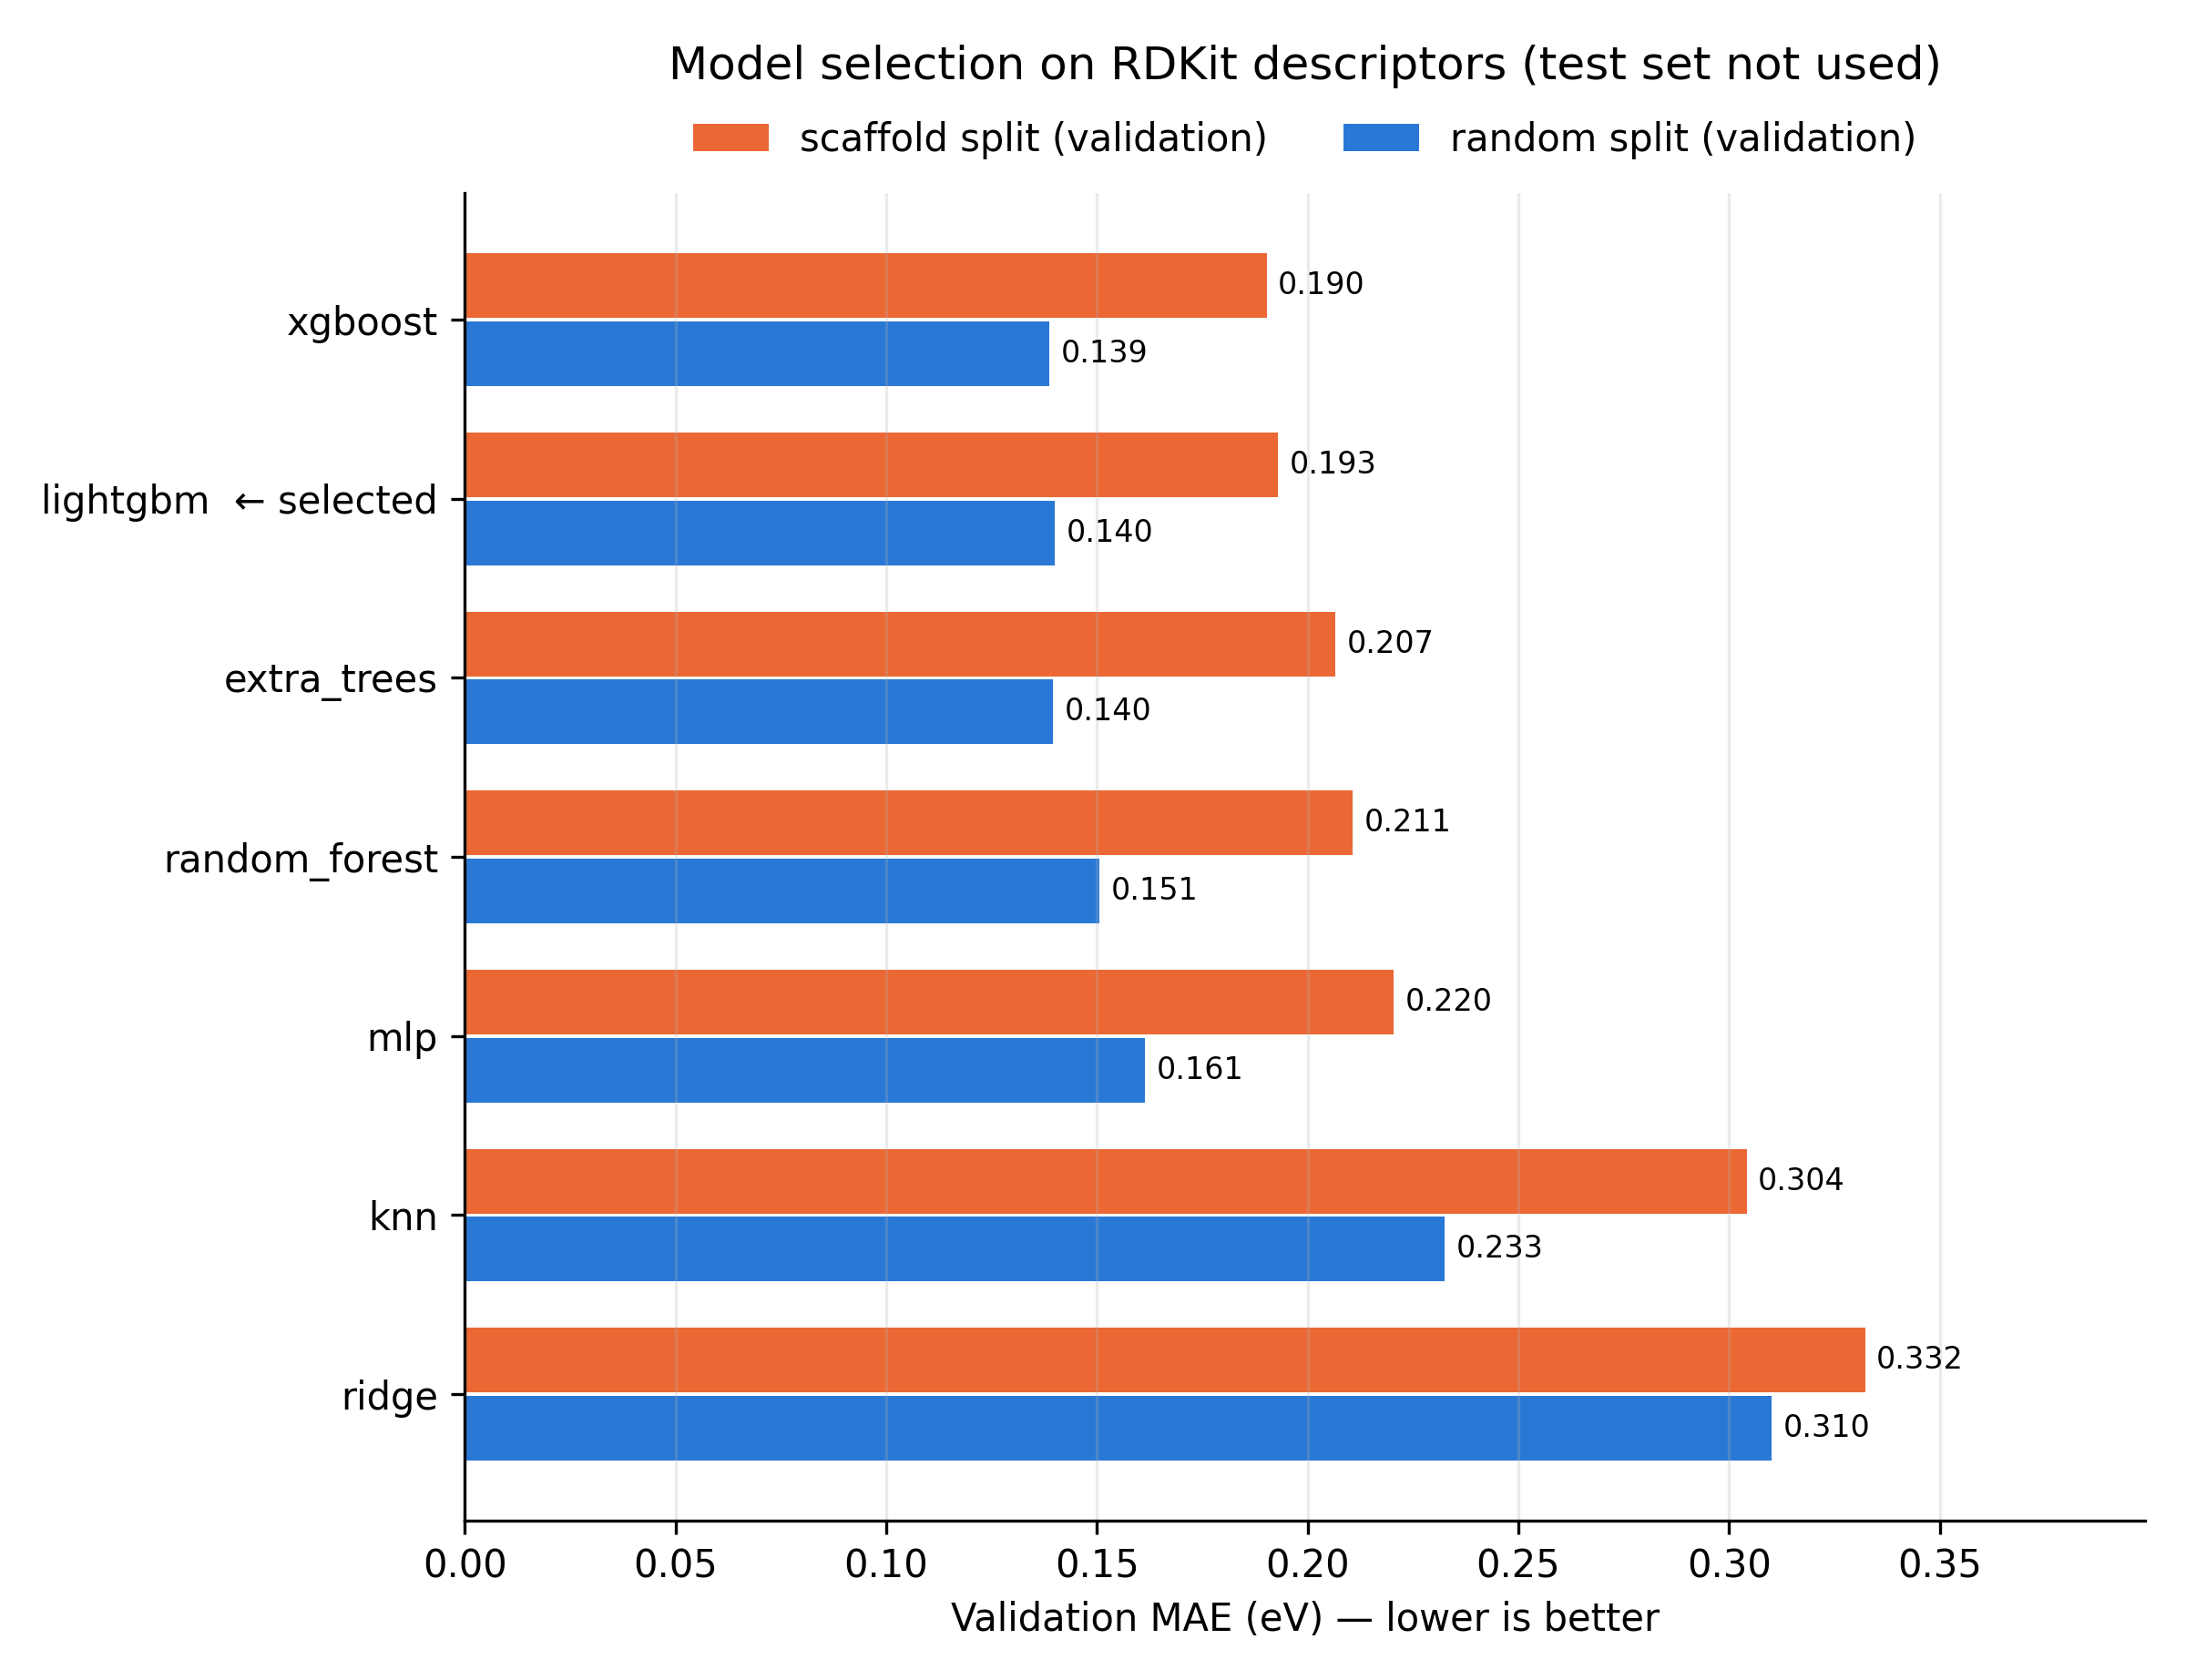

In [6]:
show("fig0_model_selection.png")

### Step 3 — Results

| Model | Val. MAE, scaffold (eV) | Val. MAE, random (eV) | Training time (min) | Model size (MB) |
|---|---|---|---|---|
| XGBoost | **0.190** | 0.139 | 6.1 | 22 |
| LightGBM | 0.193 | 0.140 | 5.3 | 28 |
| Extra Trees | 0.207 | 0.140 | 16.8 | 1,813 |
| Random Forest | 0.211 | 0.151 | 25.7 | 2,579 |
| MLP | 0.220 | 0.161 | 12.0 | 7 |
| k-nearest neighbours | 0.304 | 0.233 | 0.2 | 76 |
| Ridge | 0.332 | 0.310 | 0.2 | 2 |

**Selected: LightGBM.** XGBoost and LightGBM differ by 0.003 eV, below the 0.01 eV threshold fixed in advance,
so they count as equally accurate, and LightGBM trains faster.

**Key findings**
- **The ranking depends on the split:** on the random split Extra Trees, XGBoost and LightGBM are tied;
  on the scaffold split the two boosters are about 0.015 eV better.
- **The nonlinear models are 30–50% less accurate on unseen scaffolds** than on the random split.

## Step 4 — Comparison of molecular representations

**Goal:** find which 2D representation predicts the HOMO–LUMO gap best, and how much accuracy is lost on
unseen scaffolds.

- **Model:** LightGBM with the hyperparameters selected in Step 3, unchanged for every representation
- **Representations:** RDKit descriptors (190), Morgan count fingerprint (2,048), and both combined (2,238)
- **Protocol:** trained on *train*, early stopping on *validation*, scored once on *test*;
  random and scaffold split, 3 seeds each; a mean-value baseline is scored on the same test sets
- **Reported:** test MAE, RMSE and R² as mean ± standard deviation over seeds

**Output:** `results/representations_summary.csv`, `results/figures/fig1_representations.png`,
and the test predictions of every run (used later for error analysis)

In [7]:
!python scripts/04_compare_representations.py

Model (from step 3): lightgbm  {'reg_lambda': 0.0, 'num_leaves': 63, 'min_child_samples': 20, 'learning_rate': 0.03, 'colsample_bytree': 0.3}
  mean_baseline  random    seed 0 | MAE 1.051 eV | cached
  mean_baseline  random    seed 1 | MAE 1.053 eV | trained in 0.0 min
  mean_baseline  random    seed 2 | MAE 1.056 eV | trained in 0.0 min
  mean_baseline  scaffold  seed 0 | MAE 1.116 eV | cached
  mean_baseline  scaffold  seed 1 | MAE 1.096 eV | trained in 0.0 min
  mean_baseline  scaffold  seed 2 | MAE 1.119 eV | trained in 0.0 min

descriptors: 190 features
  descriptors    random    seed 0 | MAE 0.138 eV | cached
  descriptors    random    seed 1 | MAE 0.138 eV | trained in 3.7 min
  descriptors    random    seed 2 | MAE 0.137 eV | trained in 5.8 min
  descriptors    scaffold  seed 0 | MAE 0.193 eV | cached
  descriptors    scaffold  seed 1 | MAE 0.179 eV | trained in 5.5 min
  descriptors    scaffold  seed 2 | MAE 0.179 eV | trained in 5.4 min

morgan: 2,048 features
  morgan       

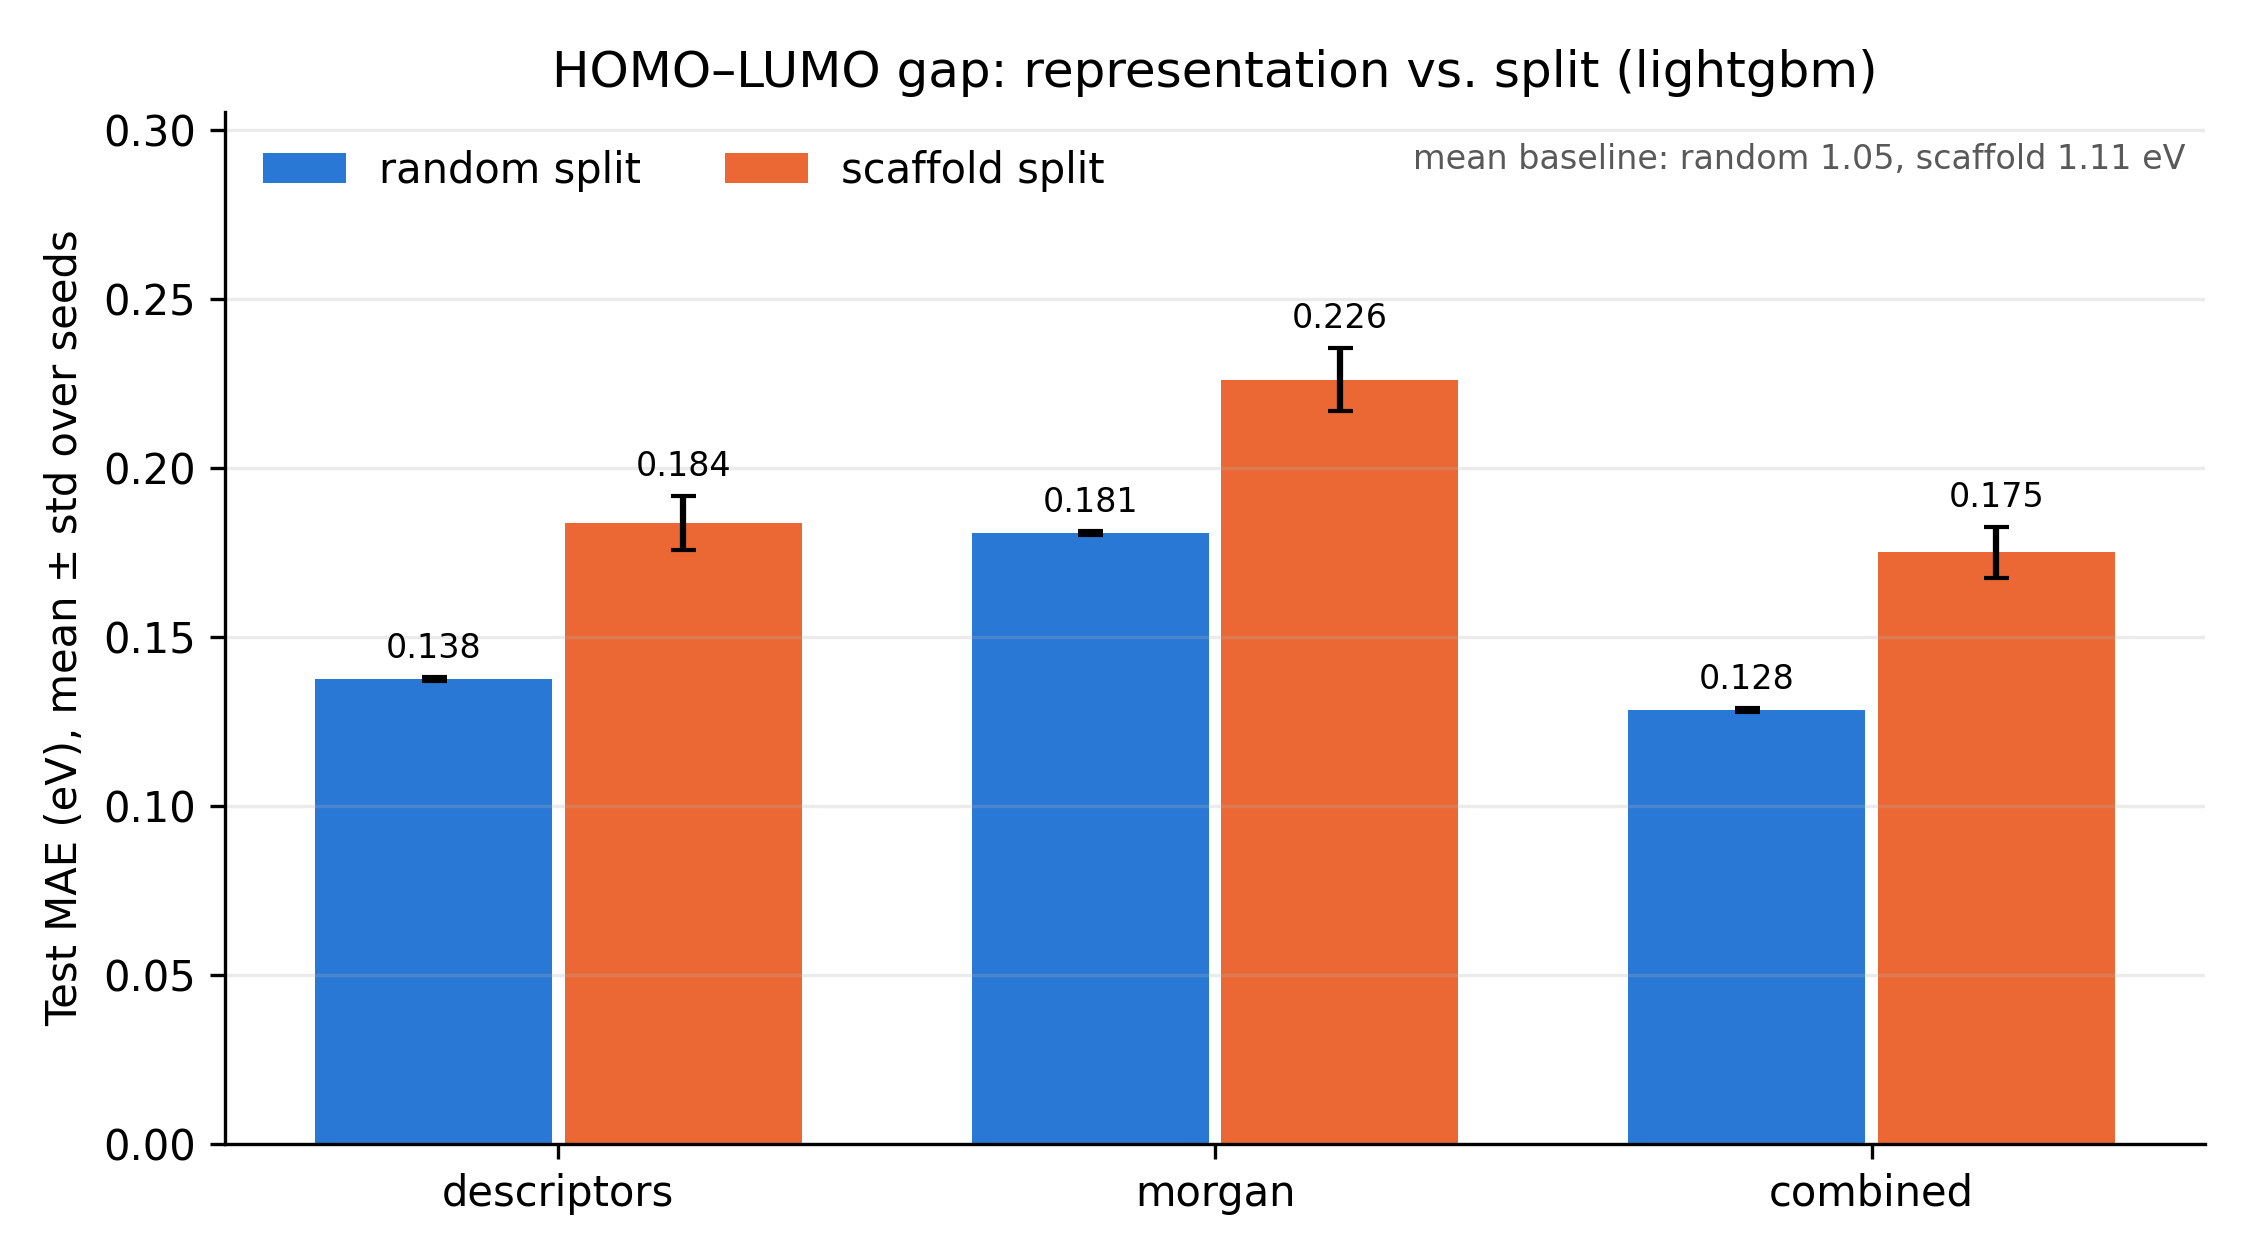

In [8]:
show("fig1_representations.png")

### Step 4 — Results

Test MAE (eV), mean ± std over 3 seeds (LightGBM, same model for every representation):

| Representation | Random split | Scaffold split | Penalty on unseen scaffolds |
|---|---|---|---|
| **Descriptors + Morgan** | **0.128 ± 0.001** | **0.175 ± 0.008** | +0.047 eV (+37%) |
| RDKit descriptors | 0.138 ± 0.001 | 0.184 ± 0.008 | +0.046 eV (+33%) |
| Morgan fingerprint | 0.181 ± 0.001 | 0.226 ± 0.009 | +0.045 eV (+25%) |
| Mean-value baseline | 1.053 ± 0.003 | 1.110 ± 0.012 | |

**Key findings**
- **Combining descriptors and fingerprints works best.** On the scaffold split it beats descriptors alone
  in every seed (by 0.008–0.009 eV, paired comparison on the same split).
- **Morgan fingerprints alone are the weakest.** Possible reason: they count local substructures, while
  the gap depends on more global properties such as conjugation.
- **Unseen scaffolds cost about 0.045 eV for every representation.** A better representation lowers the
  error overall but does not close the generalization gap.
- **The 0.01 eV threshold of Step 3 is justified:** the seed-to-seed spread on the scaffold split is about 0.008 eV.

## Step 5 — Learning curves

**Goal:** measure how the test error falls as the training set grows, and whether more data helps
as much for molecules with unseen scaffolds.

- **Training-set sizes:** 1k, 3k, 10k, 30k and the full training set (101k molecules);
  smaller sets are nested random subsets of the training set, different for each seed
- **Same protocol as Step 4:** LightGBM from Step 3, early stopping on validation, scored on the same test sets;
  the full-size point is reused from Step 4
- **All three representations**, random and scaffold split, 3 seeds
- **Summary per curve:** power-law fit `MAE = a · n^(-b)`; a larger exponent *b* means the error falls faster with more data

**Output:** `results/learning_curve_summary.csv`, `learning_curve_slopes.csv`, `results/figures/fig2_learning_curves.png`

In [9]:
!python scripts/05_learning_curves.py

Model (from step 3): lightgbm  {'reg_lambda': 0.0, 'num_leaves': 63, 'min_child_samples': 20, 'learning_rate': 0.03, 'colsample_bytree': 0.3}

descriptors: 190 features
  descriptors  random    seed 0  n=  1,000 | MAE 0.299 eV | cached
  descriptors  random    seed 0  n=  3,000 | MAE 0.249 eV | cached
  descriptors  random    seed 0  n= 10,000 | MAE 0.201 eV | cached
  descriptors  random    seed 0  n= 30,000 | MAE 0.166 eV | cached
  descriptors  random    seed 0  n=101,247 | MAE 0.138 eV | from step 4
  descriptors  random    seed 1  n=  1,000 | MAE 0.303 eV | cached
  descriptors  random    seed 1  n=  3,000 | MAE 0.250 eV | cached
  descriptors  random    seed 1  n= 10,000 | MAE 0.201 eV | cached
  descriptors  random    seed 1  n= 30,000 | MAE 0.167 eV | cached
  descriptors  random    seed 1  n=101,247 | MAE 0.138 eV | from step 4
  descriptors  random    seed 2  n=  1,000 | MAE 0.296 eV | cached
  descriptors  random    seed 2  n=  3,000 | MAE 0.246 eV | cached
  descriptors  ra

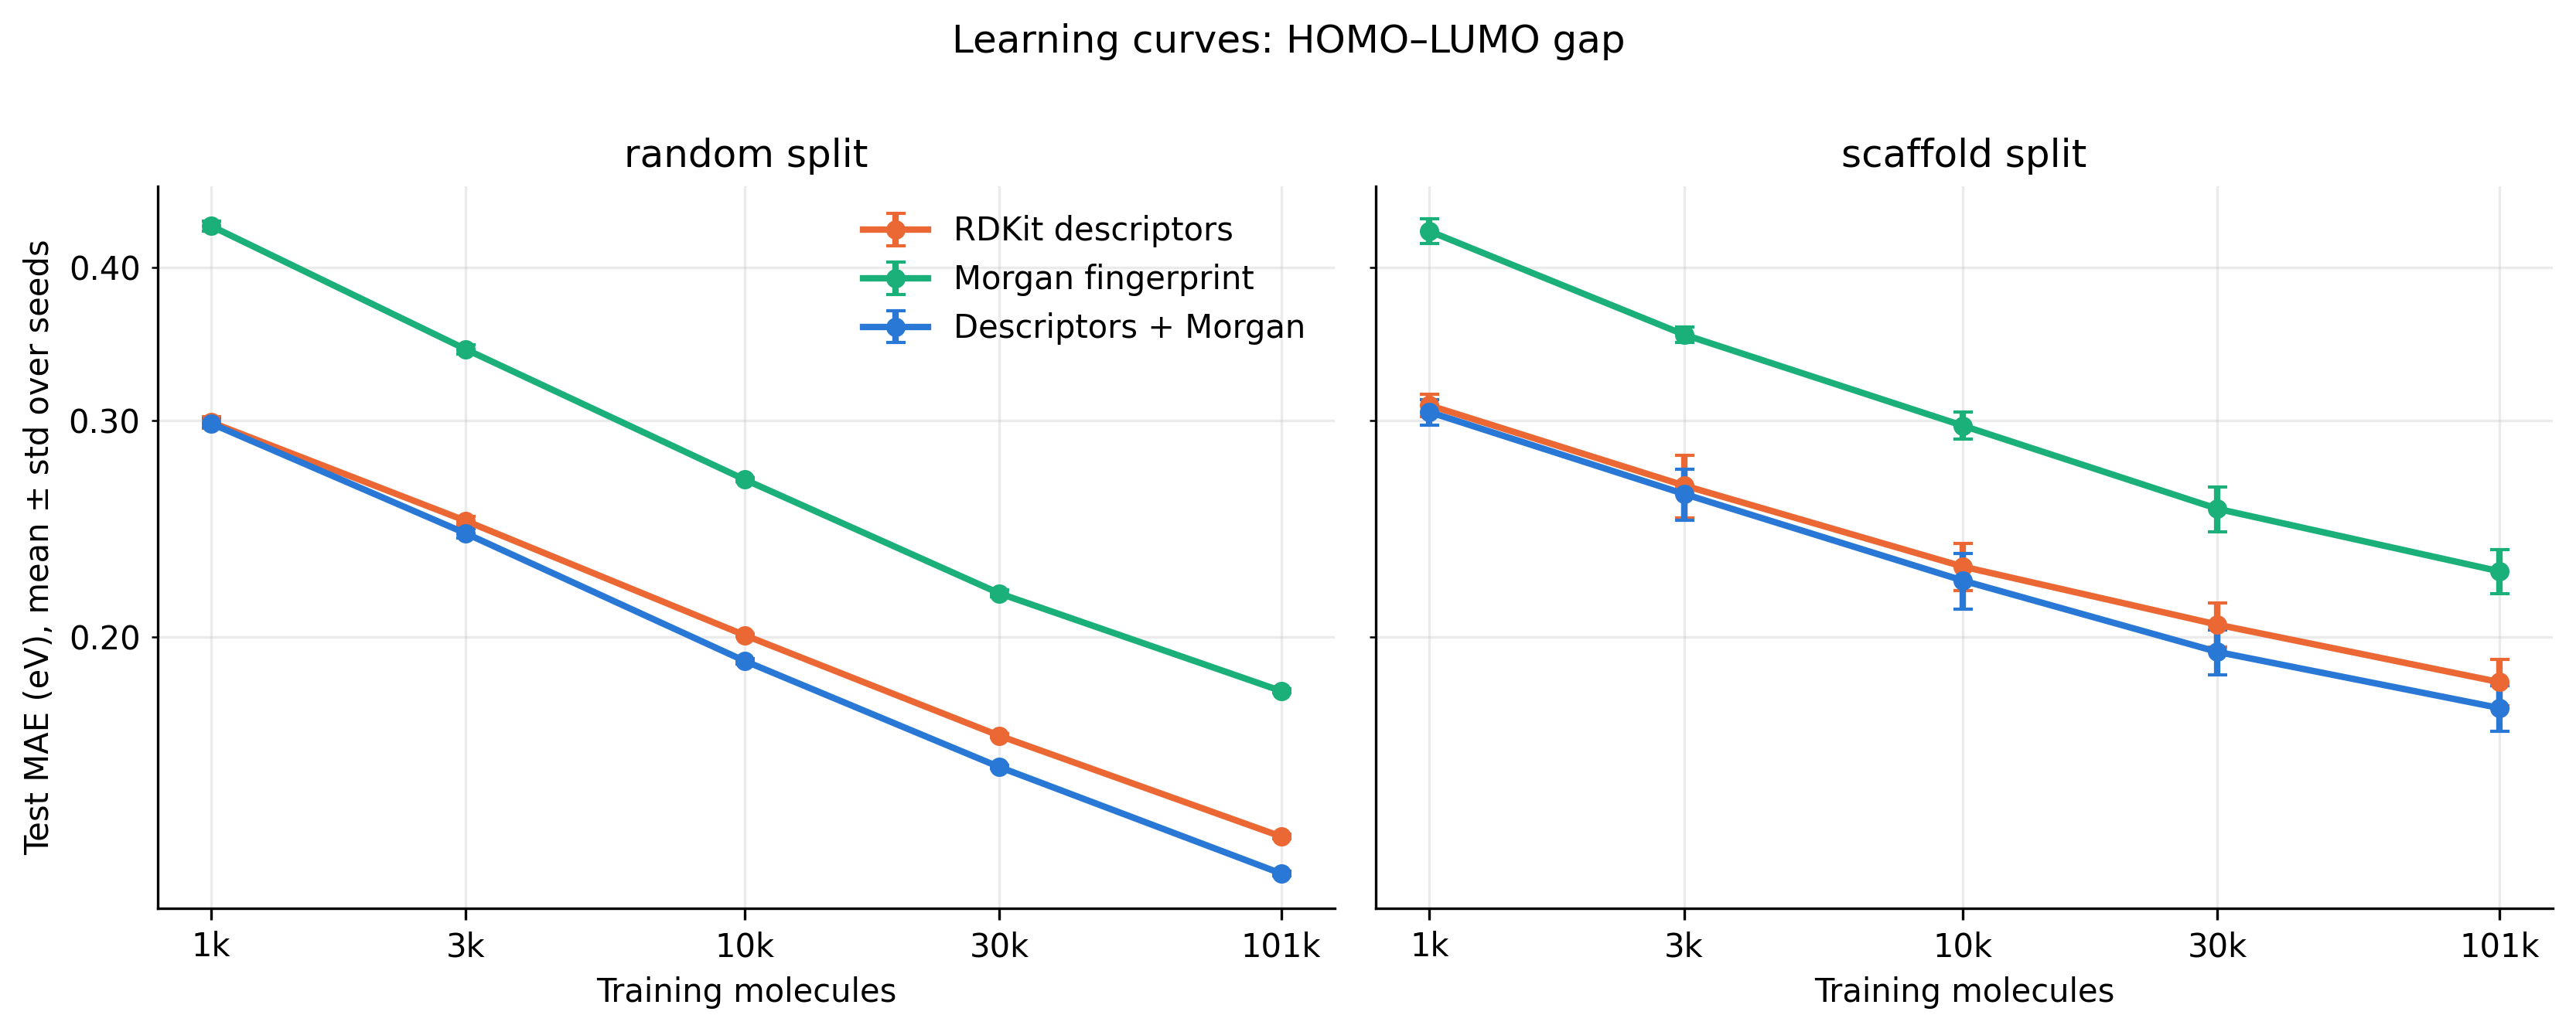

In [10]:
show("fig2_learning_curves.png")

### Step 5 — Results (mean ± std over 3 seeds)

Test MAE (eV) as a function of training-set size (LightGBM, descriptors + Morgan):

| Training molecules | Random split | Scaffold split | Gap between splits |
|---|---|---|---|
| 1,000 | 0.298 ± 0.002 | 0.305 ± 0.007 | 0.007 |
| 3,000 | 0.243 ± 0.002 | 0.261 ± 0.013 | 0.018 |
| 10,000 | 0.191 ± 0.001 | 0.222 ± 0.012 | 0.031 |
| 30,000 | 0.157 ± 0.000 | 0.194 ± 0.008 | 0.037 |
| 101,247 | 0.128 ± 0.001 | 0.175 ± 0.008 | 0.047 |

Power-law fit `MAE = a · n^(-b)` (larger *b* = error falls faster with more data):

| Representation | *b*, random | *b*, scaffold | Lower on scaffolds by |
|---|---|---|---|
| Descriptors + Morgan | 0.184 | 0.122 | 34% |
| RDKit descriptors | 0.169 | 0.112 | 34% |
| Morgan fingerprint | 0.191 | 0.139 | 27% |

**Key findings**
- **The gap between the splits grows with more data** (0.007 → 0.047 eV): extra data mainly improves
  interpolation between similar molecules.
- **On unseen scaffolds the error falls 27–34% more slowly.** Extrapolating the fit, halving the error would
  need about 40× more data on the random split but about 300× more on the scaffold split. This is a rough
  extrapolation, but it suggests that new chemotypes need better representations, not just more data.
- **Adding Morgan fingerprints helps only with enough data:** equal to descriptors at 1,000 molecules,
  0.010 eV better with the full training set.

## Step 6 — Applicability domain

**Goal:** check whether the error is larger for molecules that are unlike anything in the training set, and whether
this similarity can warn when a prediction should not be trusted.

- For every test molecule of Step 4 (LightGBM, descriptors + Morgan): **Tanimoto similarity to the most similar
  training molecule** (binary Morgan fingerprint, radius 2, 2,048 bits), compared with its absolute error.
  No new model is trained.
- **Three views:** distribution of similarities, error per similarity bin, and the error left if only predictions
  above a similarity threshold are trusted.

**Output:** `results/applicability_*.csv`, `results/figures/fig3_applicability.png`

In [11]:
!python scripts/06_applicability_domain.py

Predictions: lightgbm on 'combined' from step 4
  random_s0    | 12,656 test molecules | median similarity 0.63 | computed in 2.1 min
  random_s1    | 12,656 test molecules | median similarity 0.63 | computed in 2.1 min
  random_s2    | 12,656 test molecules | median similarity 0.63 | computed in 2.2 min
  scaffold_s0  | 12,657 test molecules | median similarity 0.52 | computed in 2.1 min
  scaffold_s1  | 12,657 test molecules | median similarity 0.55 | computed in 2.1 min
  scaffold_s2  | 12,657 test molecules | median similarity 0.52 | computed in 2.1 min

1) Similarity of test molecules to the training set, and its link to the error (mean ± std over seeds):
   split median similarity   share < 0.5 Spearman(sim, |error|)      MAE (eV)
  random     0.630 ± 0.000 0.057 ± 0.002         -0.076 ± 0.012 0.128 ± 0.001
scaffold     0.527 ± 0.016 0.333 ± 0.080         -0.128 ± 0.044 0.175 ± 0.008

2) Test MAE (eV) and number of molecules per similarity bin (mean over seeds):
                 

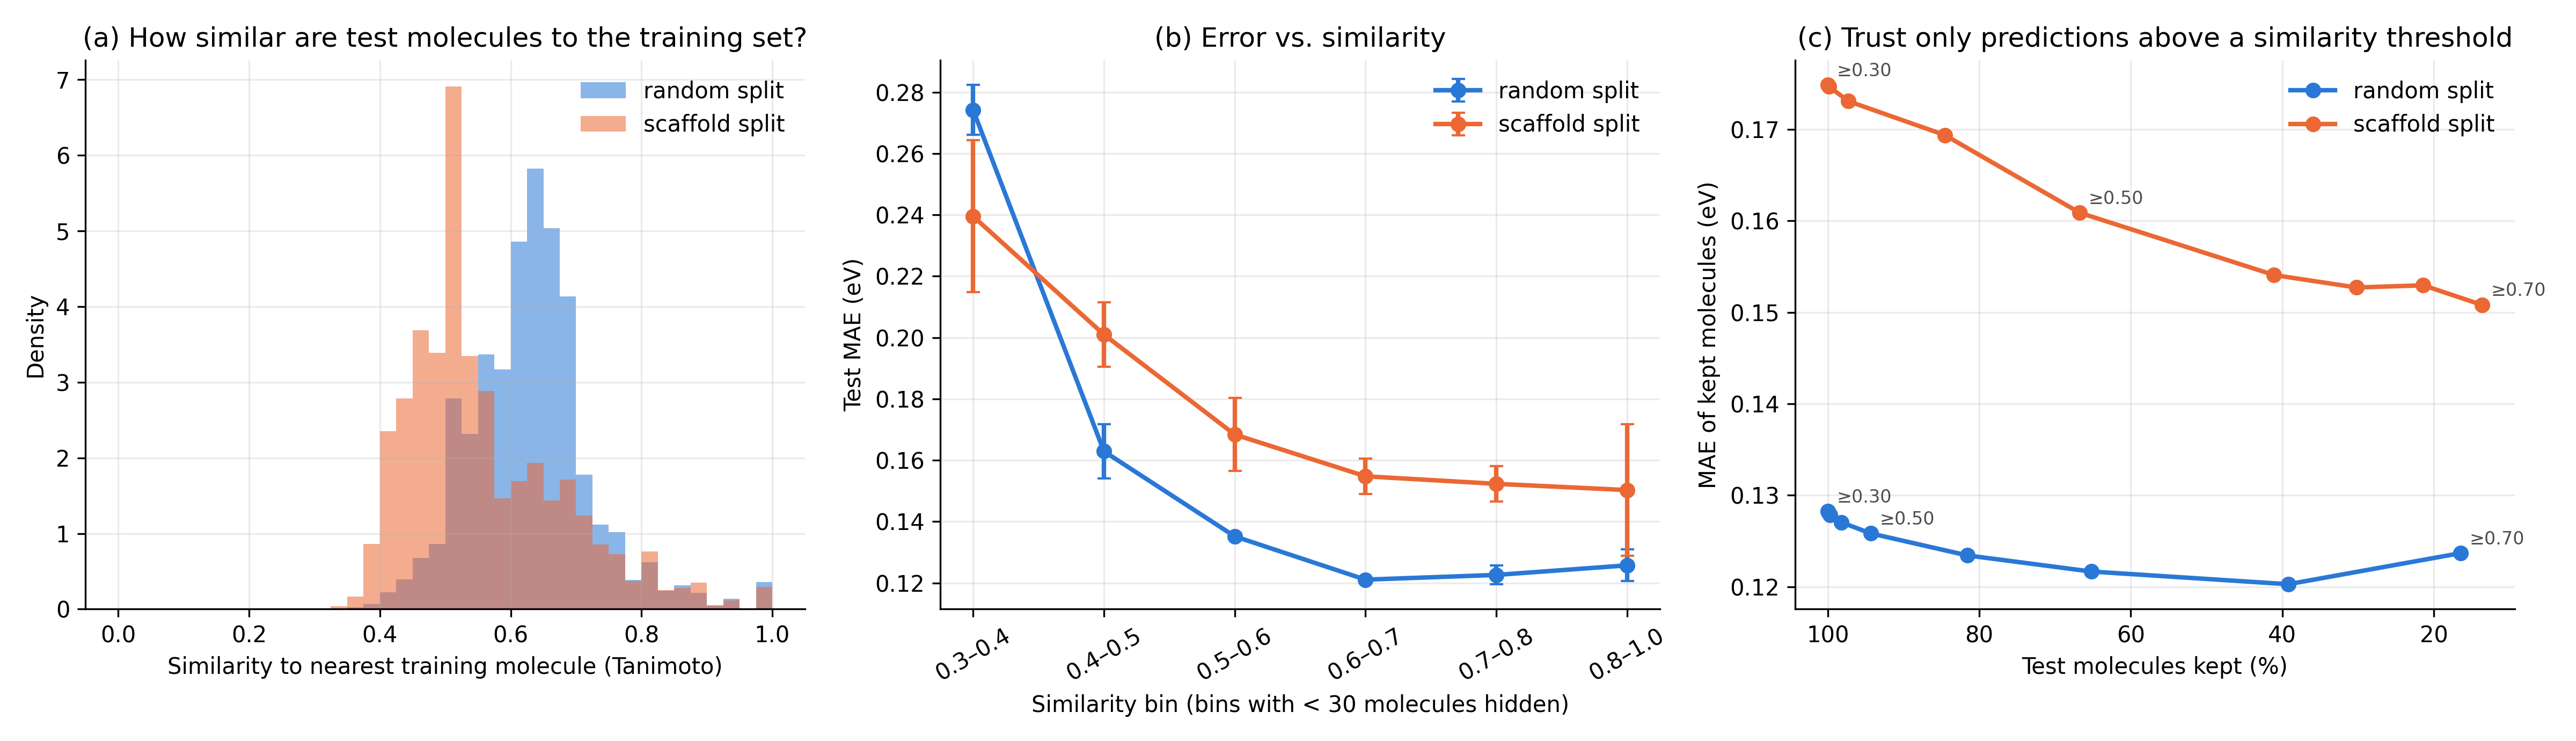

In [12]:
show("fig3_applicability.png")

### Step 6 — Results (mean over 3 seeds)

- **Scaffold-split test molecules are less similar to the training set:** median nearest-neighbour
  Tanimoto similarity 0.53 vs. 0.63; 33% below 0.5 vs. 6% on the random split.
- **On average the error grows as similarity falls**, but for a single molecule similarity is a weak
  signal (Spearman ρ ≈ −0.1).
- **Lower similarity explains only about one third of the scaffold penalty:** at the same similarity,
  scaffold-split molecules are still ~0.03 eV harder (e.g. 0.168 vs. 0.135 eV at similarity 0.5–0.6).
  Likely reason: Morgan similarity counts shared local fragments, while the gap depends on the ring system itself.
- **A similarity threshold helps only modestly:** keeping scaffold-split molecules with similarity ≥ 0.5
  retains 67% of them and lowers the MAE from 0.175 to 0.161 eV.

## Step 7 — Chemical interpretation

**Goal:** understand what drives the predictions and where the model fails.

- **A. Which descriptors matter?** LightGBM trained on the 190 RDKit descriptors (scaffold split, seed 0);
  SHAP values on 2,000 random test molecules show how much, and in which direction, each descriptor
  moves the predicted gap
- **B. Which molecules are hard?** Test errors of Step 4 grouped by structural class (aromatic ring,
  3-/4-membered ring, carbonyl, nitrile, alkyne, saturated, ...) and by the size of the true gap
- **C. Worst predictions:** the 20 molecules with the largest errors, drawn for inspection

**Output:** `chemistry_shap_importance.csv`, `chemistry_error_by_class.csv`, `chemistry_error_by_gap.csv`,
`chemistry_worst_molecules.csv`, figures `fig4`–`fig6`

In [13]:
!python scripts/07_chemical_analysis.py

Part A - which descriptors matter (SHAP)
  descriptor model, scaffold_s0 test MAE: 0.193 eV
    SHAP: 250/2,000 molecules | 0.7 min
    SHAP: 500/2,000 molecules | 1.4 min
    SHAP: 750/2,000 molecules | 2.1 min
    SHAP: 1,000/2,000 molecules | 2.8 min
    SHAP: 1,250/2,000 molecules | 3.6 min
    SHAP: 1,500/2,000 molecules | 4.3 min
    SHAP: 1,750/2,000 molecules | 5.0 min
    SHAP: 2,000/2,000 molecules | 5.7 min
         descriptor  mean_abs_shap_eV                effect
       FractionCSP3            0.2547  higher -> larger gap
      HallKierAlpha            0.1578  higher -> larger gap
           SMR_VSA7            0.1313 higher -> smaller gap
        VSA_EState2            0.1177 higher -> smaller gap
        BCUT2D_MRHI            0.1078 higher -> smaller gap
         SlogP_VSA6            0.0910 higher -> smaller gap
          SMR_VSA10            0.0634 higher -> smaller gap
            BertzCT            0.0455 higher -> smaller gap
       BCUT2D_MWLOW            0.0418 

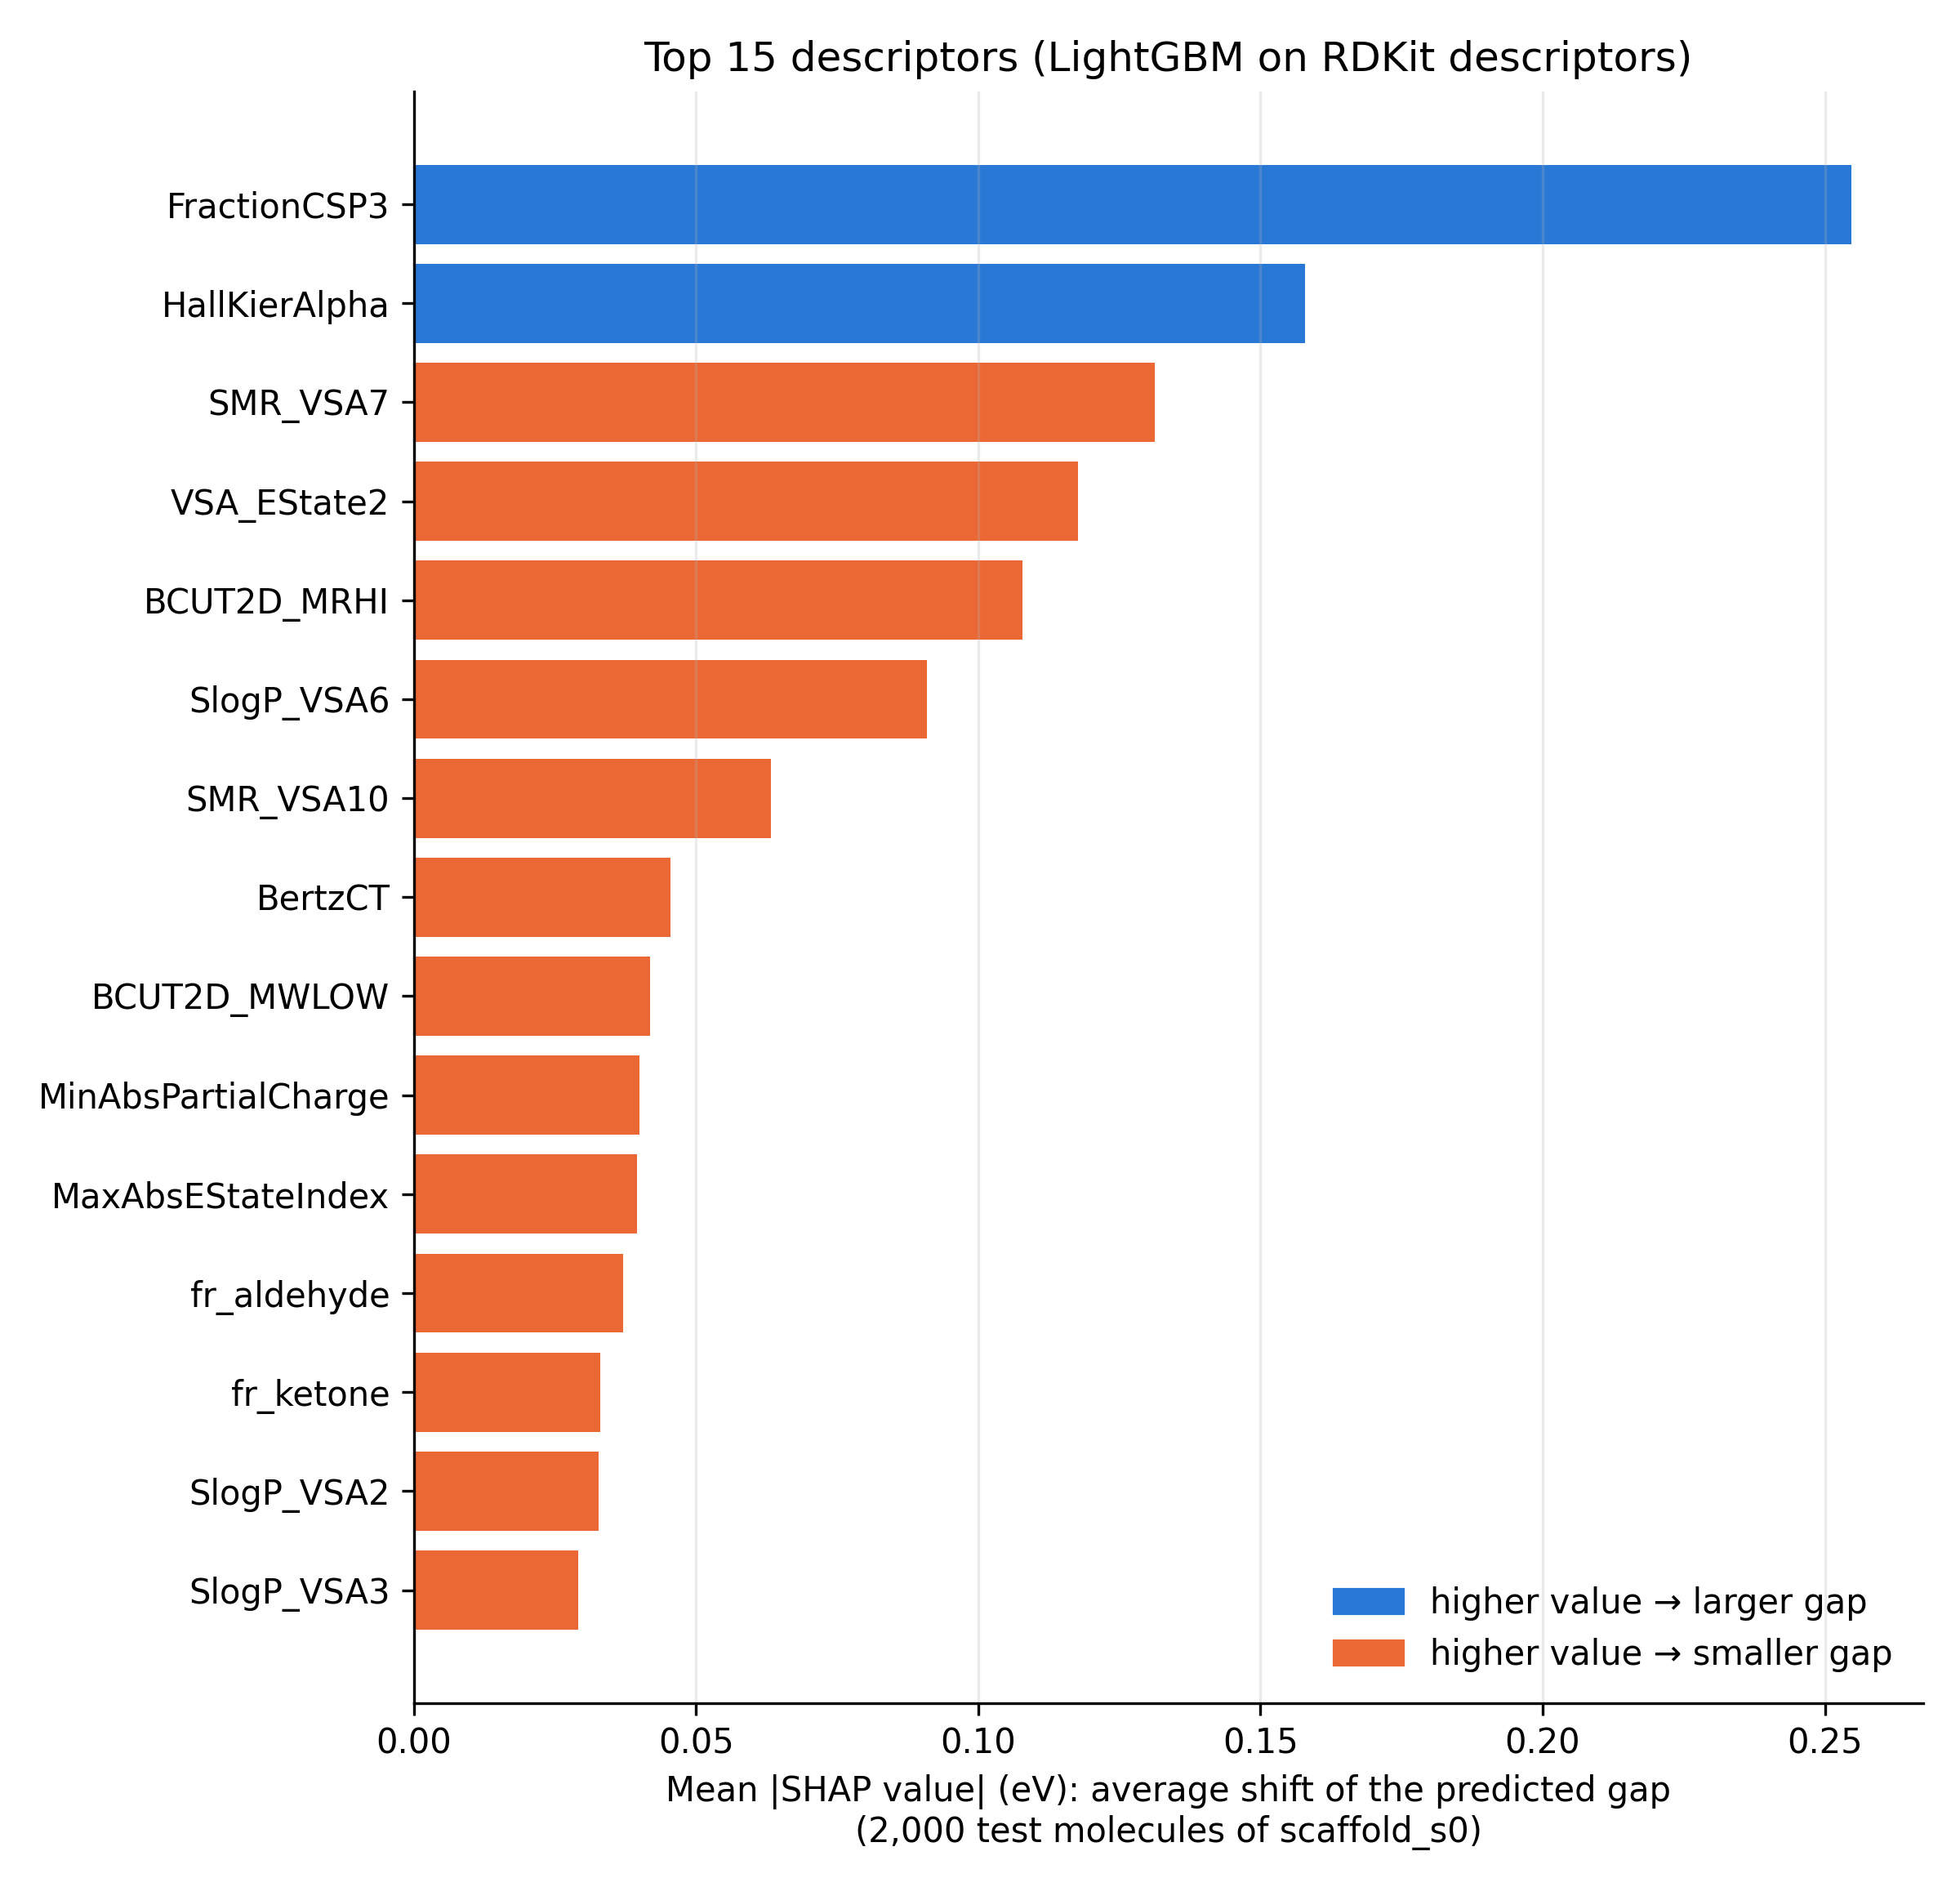

In [14]:
show("fig4_shap_importance.png")

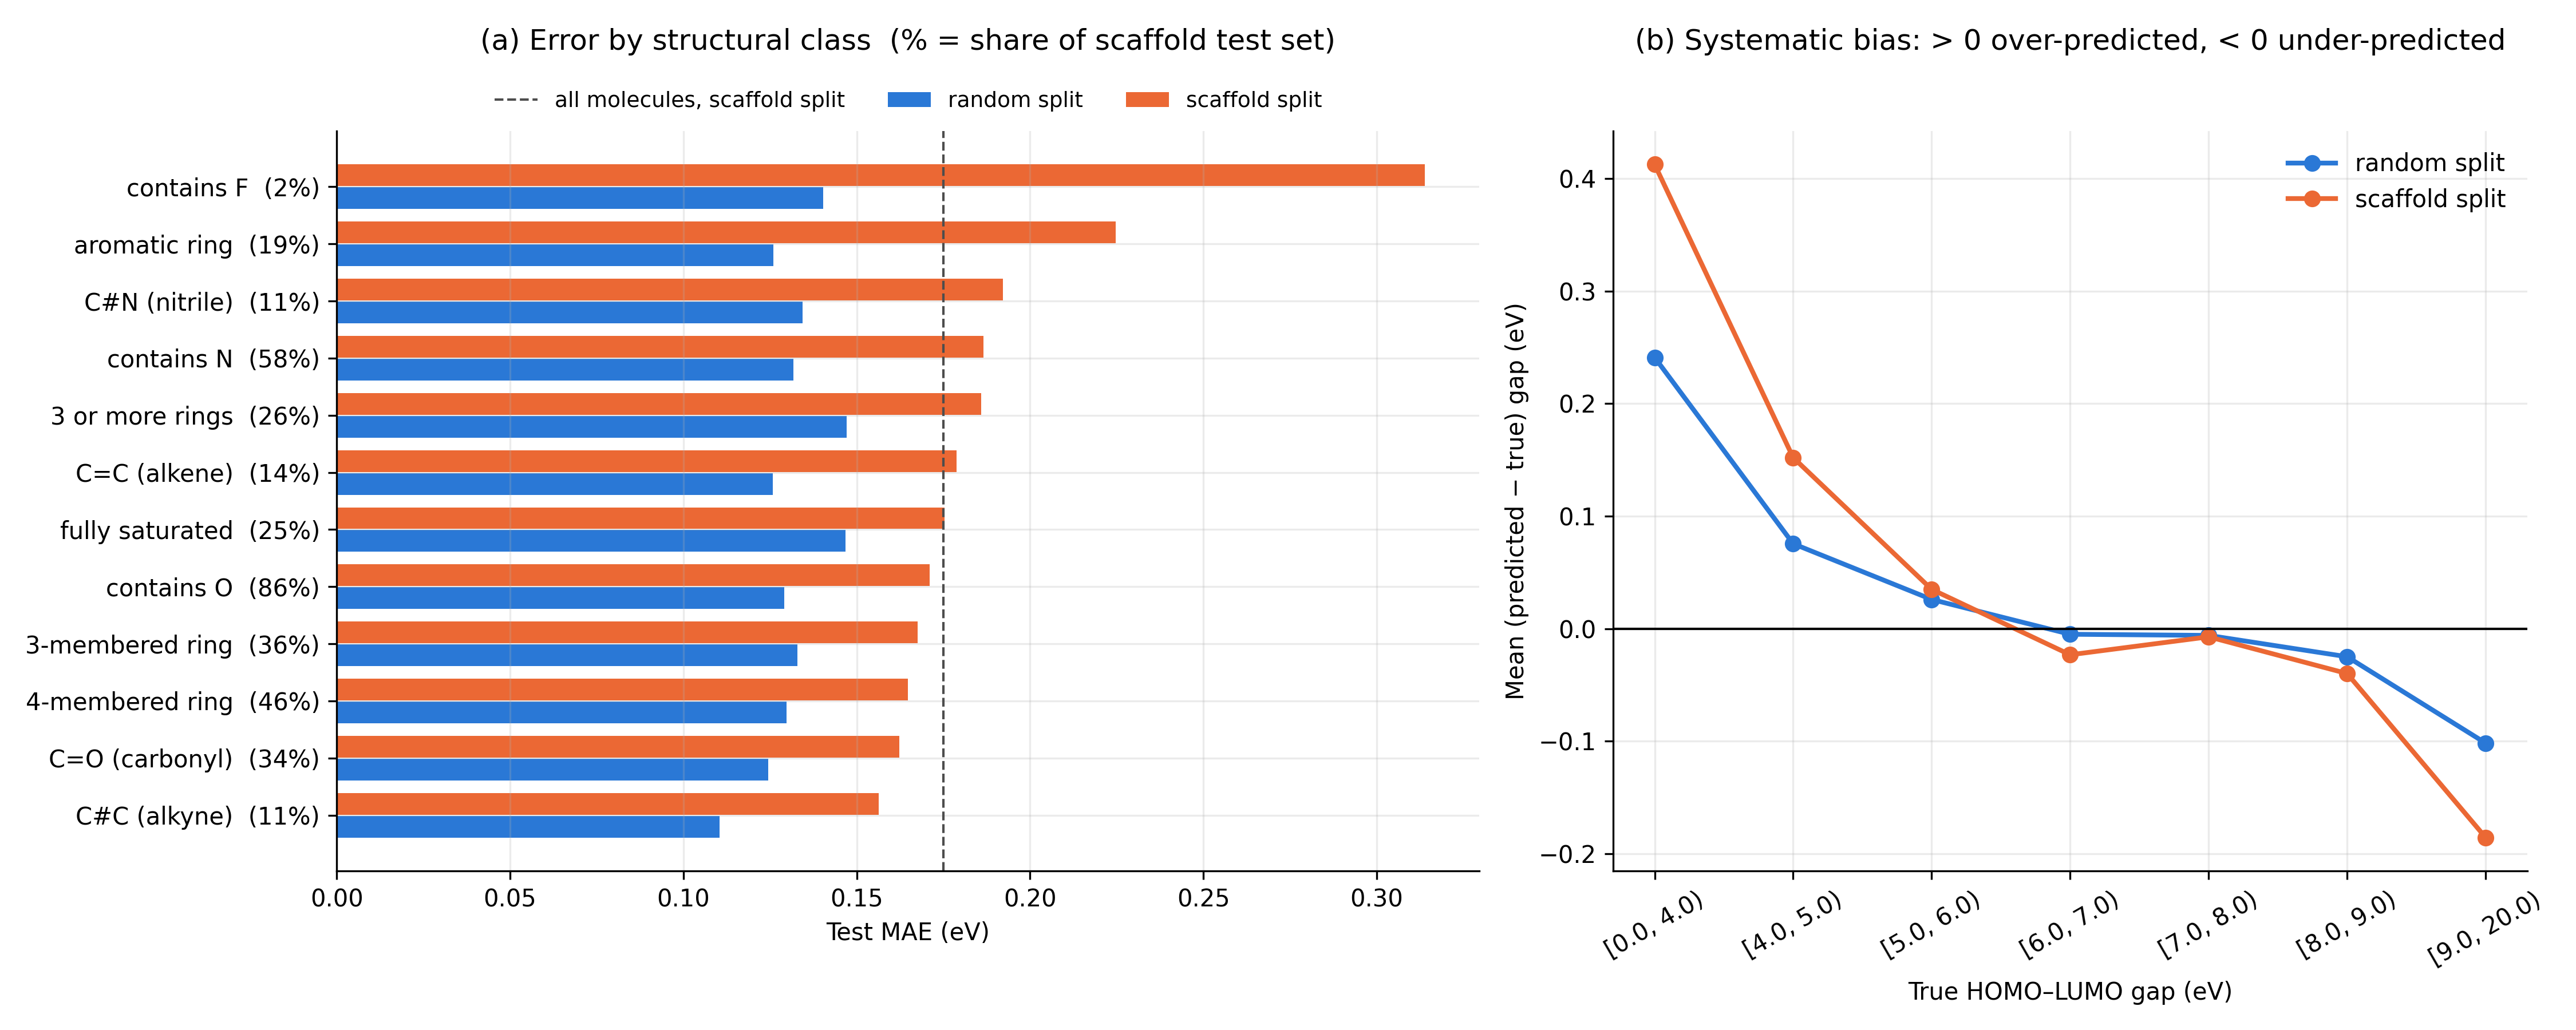

In [15]:
show("fig5_error_by_chemistry.png")

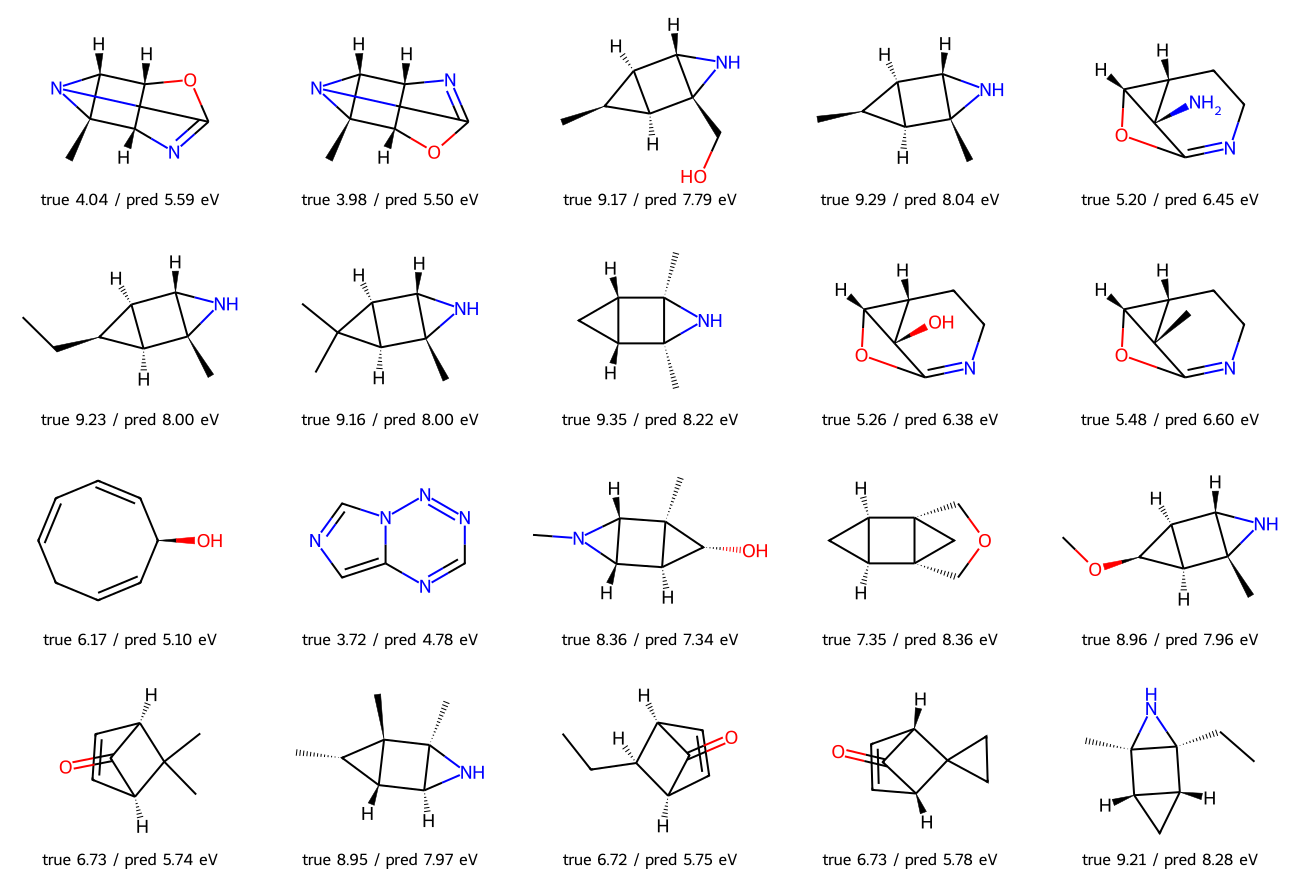

In [16]:
show("fig6_worst_molecules.png")

### Step 7 — Results

**A. SHAP:** the model learned chemically sensible rules. More sp³ carbon (FractionCSP3) and less
unsaturation (HallKierAlpha) raise the predicted gap; aromatic/sp² surface (SMR_VSA7), polarizability
(BCUT2D_MRHI) and carbonyl groups lower it.

**B. Hard molecules:** new aromatic ring systems are hardest (scaffold penalty +0.099 eV, twice the
average), fully saturated molecules easiest (+0.029 eV). The model shrinks towards the mean: small gaps
(< 4 eV) are over-predicted by +0.41 eV and large gaps (≥ 9 eV) under-predicted by −0.19 eV on the
scaffold split.

**C. Worst predictions:** strained fused polycycles (e.g. a cyclopropane fused to an aziridine,
under-predicted by ~1.2 eV), non-conjugated bicyclic enones and a non-planar eight-membered ring triene,
i.e. molecules whose electronic structure depends on 3D geometry that 2D descriptors do not capture.

## Conclusions

1. **Best representation:** RDKit descriptors + Morgan fingerprints (test MAE 0.128 eV random, 0.175 eV scaffold;
   R² 0.98 / 0.97), 6–8× better than a mean-value baseline.
2. **Unseen scaffolds cost about 0.045 eV (+25–37%) for every representation**, and more data closes this gap only slowly:
   the error falls about one third more slowly with training-set size on the scaffold split.
3. **Similarity to the training set explains only about one third of this penalty** and is a weak warning signal
   for single molecules.
4. **The model has learned sensible chemistry** but fails on new aromatic systems, on very small and very large gaps,
   and on strained polycyclic molecules whose electronics depend on 3D geometry.

**Next step:** a graph neural network (e.g. Chemprop) or a 3D-aware model, to test whether learned representations
reduce the penalty on new scaffolds.